# **Real-Life KNN Classification Project: Student Pass/Fail**

## **1. Problem Statement**

- Suppose a college wants to predict whether a student is likely to Pass or Fail based on:

- Study Hours per Day
- Attendance Percentage

- Our target variable will be:

    - 0 = Fail
    - 1 = Pass

## **2. Import Libraries**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## **3. Create the Dataset**

In [ ]:
data = {
    'Study_Hours': [
        1, 2, 1.5, 3, 2.5,
        4, 5, 4.5, 6, 5.5,
        7, 8, 7.5, 9, 10,
        2, 3.5, 4, 6.5, 8.5
    ],

    'Attendance': [
        45, 50, 48, 55, 52,
        60, 65, 63, 70, 68,
        75, 80, 78, 85, 90,
        51, 58, 62, 72, 88
    ],

    'Result': [
        0, 0, 0, 0, 0,
        1, 1, 1, 1, 1,
        1, 1, 1, 1, 1,
        0, 1, 1, 1, 1
    ]
}

df = pd.DataFrame(data)

print(df)

    Study_Hours  Attendance  Result
0           1.0          45       0
1           2.0          50       0
2           1.5          48       0
3           3.0          55       0
4           2.5          52       0
5           4.0          60       1
6           5.0          65       1
7           4.5          63       1
8           6.0          70       1
9           5.5          68       1
10          7.0          75       1
11          8.0          80       1
12          7.5          78       1
13          9.0          85       1
14         10.0          90       1
15          2.0          51       0
16          3.5          58       1
17          4.0          62       1
18          6.5          72       1
19          8.5          88       1


## **4. Separate Features and Target**

In [ ]:
X = df[['Study_Hours', 'Attendance']]
y = df['Result']

## **5. Visualize the Data**

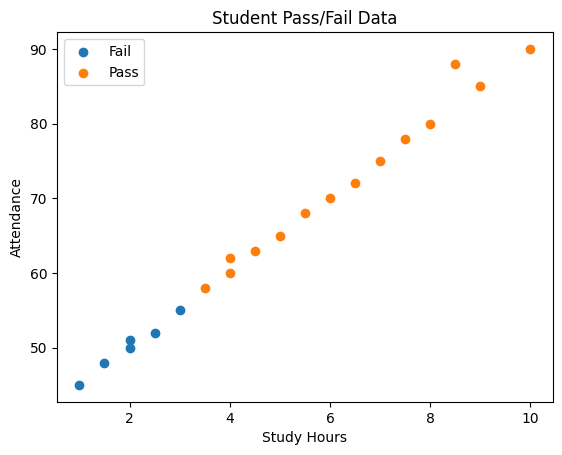

In [ ]:
plt.scatter(
    df[df['Result'] == 0]['Study_Hours'],
    df[df['Result'] == 0]['Attendance'],
    label='Fail'
)

plt.scatter(
    df[df['Result'] == 1]['Study_Hours'],
    df[df['Result'] == 1]['Attendance'],
    label='Pass'
)

plt.xlabel('Study Hours')
plt.ylabel('Attendance')
plt.title('Student Pass/Fail Data')
plt.legend()
plt.show()

## **6. Split Data into Training and Testing**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

## **7. Feature Scaling**
This step is very important for KNN.

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

## **8. Create the KNN Model**

In [ ]:
knn = KNeighborsClassifier(n_neighbors=3)

## **9. Train the Model**

In [ ]:
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

## **10. Make Predictions**

In [ ]:
y_pred = knn.predict(X_test)

print(y_pred)

[0 1 0 0]


## **11. Check Accuracy**

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 1.0


## **12. Confusion Matrix**

In [ ]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[3 0]
 [0 1]]


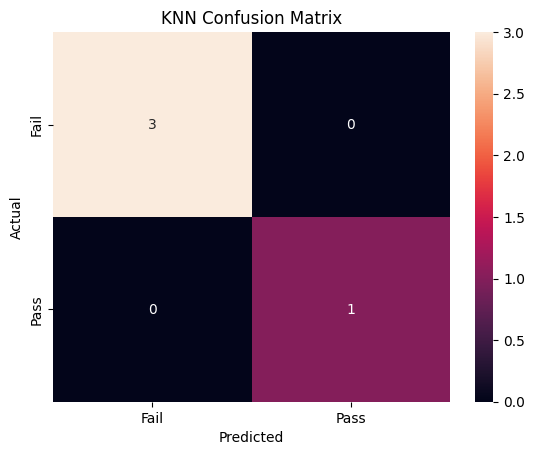

In [ ]:
import seaborn as sns

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('KNN Confusion Matrix')
plt.show()

## **13. Classification Report**

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00         1

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



## **14. Predict a New Student**

Step 1 — Create the new student's data

In [ ]:
new_student = [[5, 70]]

Step 2 — Scale the data

In [ ]:
new_student_scaled = scaler.transform(new_student)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Step 3 — Predict

In [ ]:
prediction = knn.predict(new_student_scaled)

print(prediction)

[1]


## **15. Make the Output User-Friendly**

In [ ]:
if prediction[0] == 1:
    print("Prediction: Student is likely to PASS")
else:
    print("Prediction: Student is likely to FAIL")

Prediction: Student is likely to PASS


## **16. See the Nearest Students**

This is a very useful part

In [ ]:
distances, indices = knn.kneighbors(new_student_scaled)

print("Distances:")
print(distances)

print("\nNearest Student Indices:")
print(indices)

Distances:
[[0.26220296 0.40108943 0.41478068]]

Nearest Student Indices:
[[ 8 15  0]]


In [ ]:
import pandas as pd

# -----------------------------
# 1. Create DataFrame
# -----------------------------

df = pd.DataFrame({
    'A': [10, 20, 30, 40],
    'B': [100, 200, 300, 400],
    'C': ['X', 'Y', 'Z', 'W']
})

print("Original DataFrame:")
print(df)




Original DataFrame:
    A    B  C
0  10  100  X
1  20  200  Y
2  30  300  Z
3  40  400  W


In [ ]:
# -----------------------------
# 2. x1 = ['A', 'B']
# -----------------------------

x1 = ['A', 'B']

print(x1)


['A', 'B']


In [ ]:



x2 = df[['A', 'B']]

print(x2)





    A    B
0  10  100
1  20  200
2  30  300
3  40  400


In [ ]:
x3 = df[df[['A','B']]]
print(x3)

ValueError: Boolean array expected for the condition, not int64

In [ ]:
import pandas as pd

df = pd.DataFrame({
    'A': [True, False, True, False],
    'B': [True, True, False, False],
    'C': ['X', 'Y', 'Z', 'W']
})

print("Original DataFrame:")
print(df)


# A and B used as True/False mask
x3 = df[df[['A', 'B']]]

print("\nAfter df[df[['A', 'B']]]:")
print(x3)

Original DataFrame:
       A      B  C
0   True   True  X
1  False   True  Y
2   True  False  Z
3  False  False  W

After df[df[['A', 'B']]]:
      A     B    C
0  True  True  NaN
1   NaN  True  NaN
2  True   NaN  NaN
3   NaN   NaN  NaN
